In [ ]:
!pip install -q rfdetr supervision

rfdetr is the model package.
supervision is a helper library for drawing boxes, tracking objects and counting line

In [ ]:
MODEL_SIZE = "small"        # "nano", "small", "medium", "large"
THRESHOLD = 0.5             # confidence cutoff: higher = fewer, surer detections
TRACK_CLASSES = ["person", "car", "bicycle", "motorcycle", "bus", "truck"]

MAX_FRAMES = 300            # process only the first N frames (None = whole video)
LINE_Y_FRACTION = 0.5       # counting line height: 0 = top, 1 = bottom

In [ ]:
import cv2
import numpy as np
import torch
import supervision as sv
import matplotlib.pyplot as plt
from collections import Counter
from itertools import islice

from rfdetr import RFDETRNano, RFDETRSmall, RFDETRMedium, RFDETRLarge
from rfdetr.assets.coco_classes import COCO_CLASSES

print("GPU available:", torch.cuda.is_available())

models = {"nano": RFDETRNano, "small": RFDETRSmall, "medium": RFDETRMedium, "large": RFDETRLarge}
model = models[MODEL_SIZE]()

pairs = COCO_CLASSES.items() if isinstance(COCO_CLASSES, dict) else enumerate(COCO_CLASSES)
name_to_id = {name: cid for cid, name in pairs}
id_to_name = {cid: name for name, cid in name_to_id.items()}
TRACK_IDS = [name_to_id[n] for n in TRACK_CLASSES]
print("Tracking:", TRACK_CLASSES)
print("Total classes the model knows:", len(name_to_id))

GPU available: True
[2026-10-09 11:00:19] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


[2026-10-09 11:00:19] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-09 11:00:19] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-09 11:00:20] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.
Tracking: ['person', 'car', 'bicycle', 'motorcycle', 'bus', 'truck']
Total classes the model knows: 80


In [ ]:
from google.colab import files

uploaded = files.upload()
VIDEO_PATH = list(uploaded.keys())[0]
info = sv.VideoInfo.from_video_path(VIDEO_PATH)
print(VIDEO_PATH, info)

Saving rfdetr-sample_YHrbNRtE.mp4 to rfdetr-sample_YHrbNRtE.mp4
rfdetr-sample_YHrbNRtE.mp4 VideoInfo(width=1280, height=720, fps=25.0, total_frames=408)


[2026-10-09 10:56:57] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


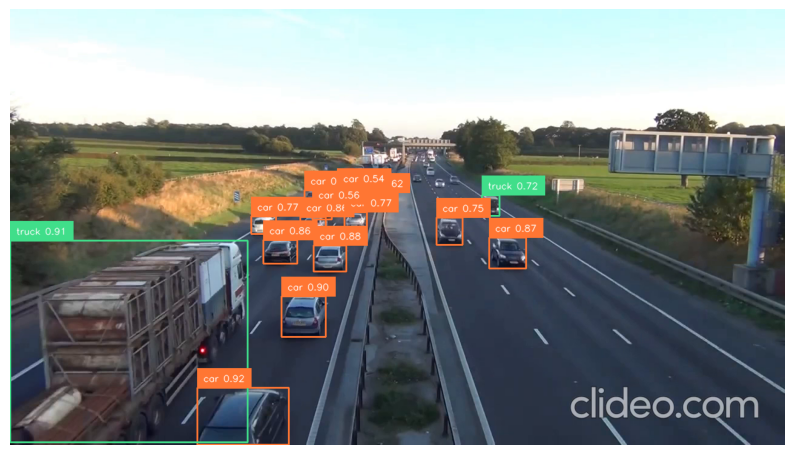

Objects found: 15


In [ ]:
frame = next(sv.get_video_frames_generator(VIDEO_PATH))
rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
det = model.predict(rgb, threshold=THRESHOLD)
det = det[np.isin(det.class_id, TRACK_IDS)]

labels = [f"{id_to_name[c]} {s:.2f}" for c, s in zip(det.class_id, det.confidence)]
preview = sv.BoxAnnotator().annotate(frame.copy(), det)
preview = sv.LabelAnnotator().annotate(preview, det, labels)
sv.plot_image(preview, size=(10, 6))
print("Objects found:", len(det))

In [ ]:
OUT_PATH = "result_raw.mp4"

tracker = sv.ByteTrack(frame_rate=int(info.fps))

line_y = int(info.height * LINE_Y_FRACTION)
line_zone = sv.LineZone(start=sv.Point(0, line_y), end=sv.Point(info.width, line_y))

box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()
trace_annotator = sv.TraceAnnotator(trace_length=30)
line_annotator = sv.LineZoneAnnotator()

frames = sv.get_video_frames_generator(VIDEO_PATH)
if MAX_FRAMES:
    frames = islice(frames, MAX_FRAMES)

counts_over_time = []

with sv.VideoSink(OUT_PATH, info) as sink:
    for frame in frames:
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        det = model.predict(rgb, threshold=THRESHOLD)
        det = det[np.isin(det.class_id, TRACK_IDS)]
        det = tracker.update_with_detections(det)

        line_zone.trigger(det)
        counts_over_time.append(Counter(id_to_name[c] for c in det.class_id))

        labels = [f"#{t} {id_to_name[c]}" for t, c in zip(det.tracker_id, det.class_id)]
        out = frame.copy()
        out = trace_annotator.annotate(out, det)
        out = box_annotator.annotate(out, det)
        out = label_annotator.annotate(out, det, labels)
        out = line_annotator.annotate(out, line_zone)
        sink.write_frame(out)

print("Frames processed:", len(counts_over_time))
print("Crossed line  IN:", line_zone.in_count, "  OUT:", line_zone.out_count)

/tmp/ipykernel_1861/3027379887.py:3: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  tracker = sv.ByteTrack(frame_rate=int(info.fps))


Frames processed: 300
Crossed line  IN: 15   OUT: 14


In [ ]:
!ffmpeg -y -loglevel error -i result_raw.mp4 -vcodec libx264 -pix_fmt yuv420p result.mp4

from IPython.display import HTML
from base64 import b64encode

data = b64encode(open("result.mp4", "rb").read()).decode()
HTML(f'<video width="700" controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>')

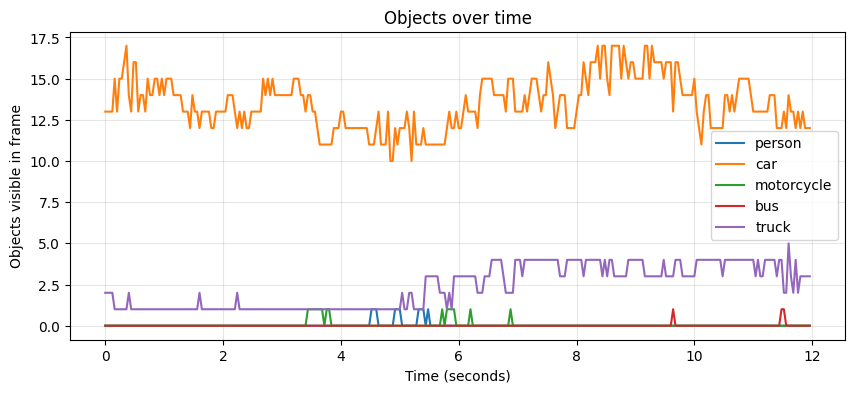

Average per frame: {'car': 13.49, 'truck': 2.35, 'motorcycle': 0.05, 'person': 0.03, 'bus': 0.01}


In [ ]:
plt.figure(figsize=(10, 4))
for name in TRACK_CLASSES:
    series = [c.get(name, 0) for c in counts_over_time]
    if sum(series) > 0:
        plt.plot(np.arange(len(series)) / info.fps, series, label=name)
plt.xlabel("Time (seconds)")
plt.ylabel("Objects visible in frame")
plt.title("Objects over time")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

total = Counter()
for c in counts_over_time:
    total.update(c)
print("Average per frame:", {k: round(v / len(counts_over_time), 2) for k, v in total.items()})

In [ ]:
BENCH_SIZES = ["nano", "small", "medium", "large"]
BENCH_FRAMES = 60     # number of frames to test on
WARMUP = 5            # frames run first and not counted (GPU warm-up)

# Official numbers from the RF-DETR docs (COCO val, NVIDIA T4 + TensorRT)
PUBLISHED = {
    "nano":   {"COCO AP": 48.4, "Published ms": 2.3, "Params (M)": 30.5},
    "small":  {"COCO AP": 53.0, "Published ms": 3.5, "Params (M)": 32.1},
    "medium": {"COCO AP": 54.7, "Published ms": 4.4, "Params (M)": 33.7},
    "large":  {"COCO AP": 56.5, "Published ms": 6.8, "Params (M)": 33.9},
}

In [ ]:
bench_frames = list(islice(sv.get_video_frames_generator(VIDEO_PATH), BENCH_FRAMES))
bench_rgb = [cv2.cvtColor(f, cv2.COLOR_BGR2RGB) for f in bench_frames]
print("Test frames loaded:", len(bench_frames))

Test frames loaded: 60


In [ ]:
import time, gc

results = []

for size in BENCH_SIZES:
    m = models[size]()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    for img in bench_rgb[:WARMUP]:           # warm-up, not counted
        m.predict(img, threshold=THRESHOLD)
    torch.cuda.synchronize()

    times, n_objs, confs = [], [], []
    for img in bench_rgb:
        t0 = time.perf_counter()
        d = m.predict(img, threshold=THRESHOLD)
        torch.cuda.synchronize()
        times.append((time.perf_counter() - t0) * 1000)

        d = d[np.isin(d.class_id, TRACK_IDS)]
        n_objs.append(len(d))
        confs.extend(d.confidence.tolist())

    results.append({
        "Model": f"RF-DETR {size}",
        "Family": "RF-DETR",
        "ms/frame": np.mean(times),
        "FPS": 1000 / np.mean(times),
        "GPU memory (MB)": torch.cuda.max_memory_allocated() / 1e6,
        "Avg objects/frame": np.mean(n_objs),
        "Avg confidence": np.mean(confs) if confs else 0,
        "COCO AP": PUBLISHED[size]["COCO AP"],
        "Params (M)": PUBLISHED[size]["Params (M)"],
    })
    print(f"{size:7s} done: {np.mean(times):.1f} ms/frame")

    del m
    gc.collect()
    torch.cuda.empty_cache()

[2026-10-09 11:02:31] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-nano.pth


/root/.roboflow/models/rf-detr-nano.pth:   0%|          | 0.00/349M [00:00<?, ?iB/s]

[2026-10-09 11:02:38] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-nano.pth


[2026-10-09 11:02:38] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-09 11:02:38] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-09 11:02:39] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-nano.pth already exists with correct MD5 hash.


...

[2026-10-09 11:03:04] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-large-2026.pth


[2026-10-09 11:03:04] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-09 11:03:04] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-09 11:03:05] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-large-2026.pth already exists with correct MD5 hash.


[2026-10-09 11:03:05] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


large   done: 51.7 ms/frame


In [ ]:
import pandas as pd

df = pd.DataFrame(results).round(2)
df

,Model,Family,ms/frame,FPS,GPU memory (MB),Avg objects/frame,Avg confidence,COCO AP,Params (M)
0,RF-DETR nano,RF-DETR,19.89,50.27,168.25,12.45,0.78,48.4,30.5
1,RF-DETR small,RF-DETR,31.87,31.38,193.79,15.20,0.78,53.0,32.1
2,RF-DETR medium,RF-DETR,39.42,25.37,211.66,15.57,0.77,54.7,33.7
3,RF-DETR large,RF-DETR,51.71,19.34,241.58,16.08,0.76,56.5,33.9


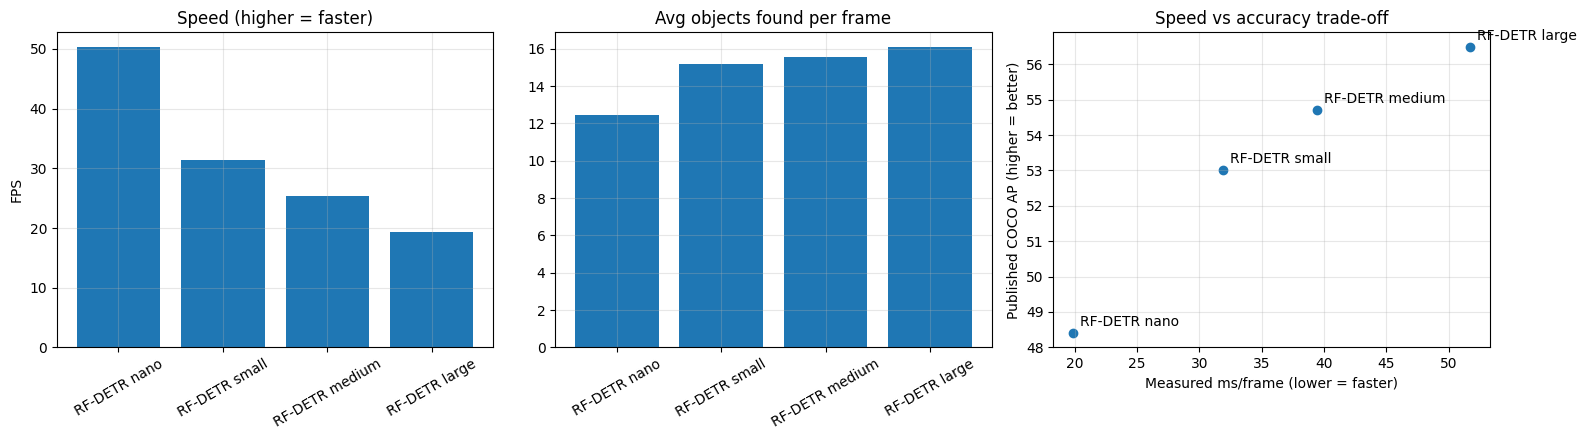

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].bar(df["Model"], df["FPS"])
axes[0].set_title("Speed (higher = faster)")
axes[0].set_ylabel("FPS")
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(df["Model"], df["Avg objects/frame"])
axes[1].set_title("Avg objects found per frame")
axes[1].tick_params(axis="x", rotation=30)

axes[2].scatter(df["ms/frame"], df["COCO AP"])
for _, r in df.iterrows():
    axes[2].annotate(r["Model"], (r["ms/frame"], r["COCO AP"]),
                     textcoords="offset points", xytext=(5, 5))
axes[2].set_title("Speed vs accuracy trade-off")
axes[2].set_xlabel("Measured ms/frame (lower = faster)")
axes[2].set_ylabel("Published COCO AP (higher = better)")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()